In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_curve, auc, precision_recall_curve
from sklearn.metrics import roc_curve, auc, precision_recall_curve
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
from sklearn.preprocessing import label_binarize

In [ ]:

path = "/content/Dataset Smart Irrigation Systems in Agriculture.csv"
data = pd.read_csv(path)



In [ ]:
print("Dataset Information:")
print(data.info())

print("\nFirst 5 rows of the dataset:")
print(data.head())

# 2. Detect missing values
print("\nMissing values in each column:")
print(data.isnull().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4688 entries, 0 to 4687
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id            4688 non-null   int64  
 1   temperature   4688 non-null   float64
 2   pressure      4688 non-null   float64
 3   altitude      4688 non-null   object 
 4   soilmiosture  4688 non-null   int64  
 5   note          4688 non-null   int64  
 6   status        4688 non-null   int64  
 7   class         4688 non-null   object 
 8   date          4688 non-null   object 
 9   time          4688 non-null   object 
dtypes: float64(2), int64(4), object(4)
memory usage: 366.4+ KB
None

First 5 rows of the dataset:
   id  temperature  pressure altitude  soilmiosture  note  status     class  \
0   1        29.10   9984.53   12.21-           377     0       0  Very Dry   
1   2        29.08   9984.36   12.22-           379     0       0  Very Dry   
2   3        29.06  

In [ ]:
data['altitude'] = data['altitude'].str.replace('[^0-9.]', '', regex=True).astype(float)

In [ ]:
label_encoder = LabelEncoder()
data['class_encoded'] = label_encoder.fit_transform(data['class'])

In [ ]:
numeric_data_with_class = data.select_dtypes(include=[np.number])

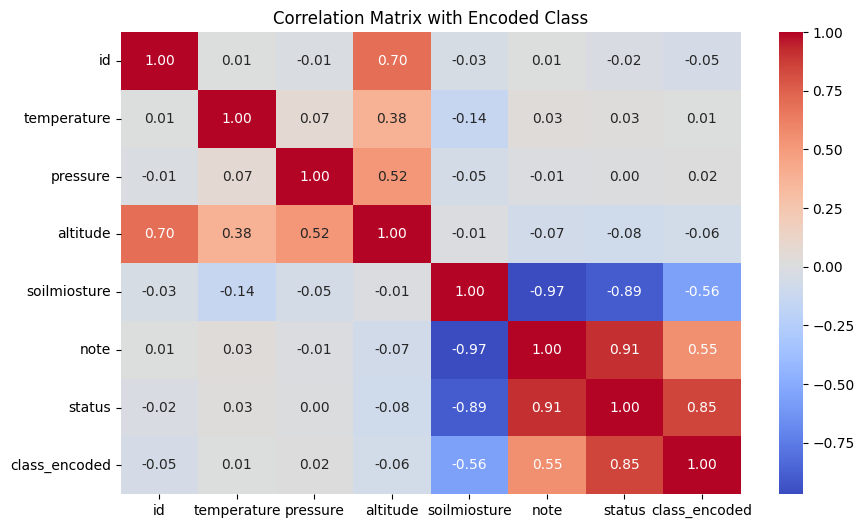

In [ ]:
correlation_matrix = numeric_data_with_class.corr()

# Visualize the correlation matrix
plt.figure(figsize=(10, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix with Encoded Class')
plt.show()

In [ ]:
X = data.drop(columns=['class', 'note', 'date', 'time', 'class_encoded'])  # Drop non-numerical or target columns
y = data['class_encoded']  # Target variable (encoded 'class')

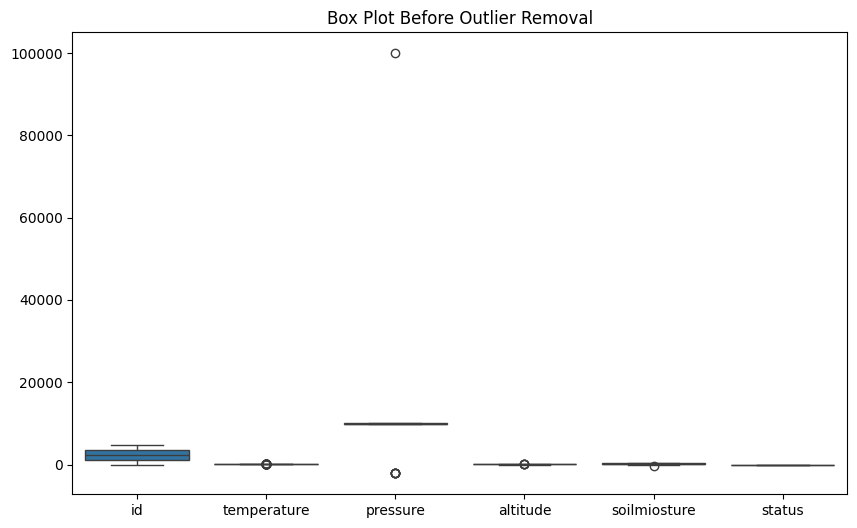

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create box plot for X before outlier removal
plt.figure(figsize=(10, 6))
sns.boxplot(data=X)
plt.title("Box Plot Before Outlier Removal")
plt.show()

In [ ]:
import numpy as np
import pandas as pd

def remove_outliers_iqr(X, y):
    # Calculate Q1 (25th percentile) and Q3 (75th percentile)
    Q1 = X.quantile(0.25)
    Q3 = X.quantile(0.75)
    IQR = Q3 - Q1

    # Define the lower and upper bounds to filter out the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Remove the rows where any of the columns have outliers
    mask = ~((X < lower_bound) | (X > upper_bound)).any(axis=1)

    X_no_outliers = X[mask]
    y_no_outliers = y[mask]

    return X_no_outliers, y_no_outliers

X_no_outliers, y_no_outliers = remove_outliers_iqr(X, y)


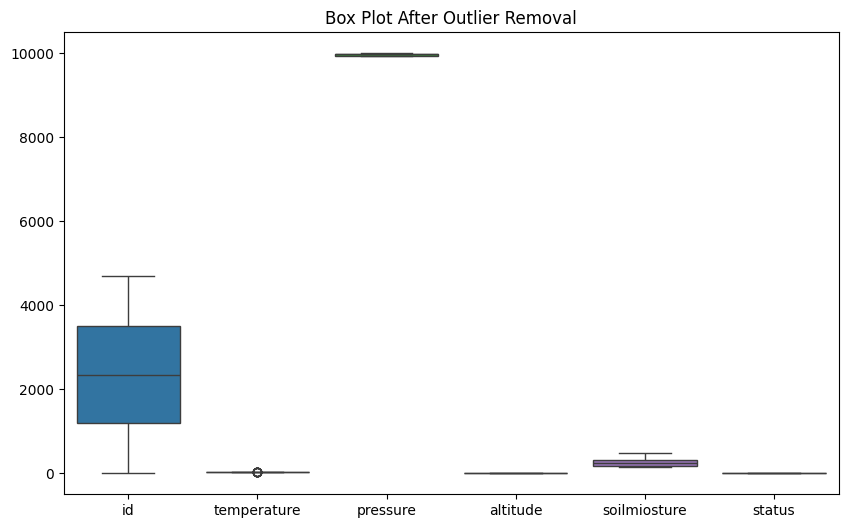

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create box plot for X after outlier removal
plt.figure(figsize=(10, 6))
sns.boxplot(data=X_no_outliers)
plt.title("Box Plot After Outlier Removal")
plt.show()

In [ ]:
# 6. Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_no_outliers, y_no_outliers, test_size=0.2, random_state=42)

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
X_train_scaled

array([[ 1.11636883, -0.8702844 , -1.32008622,  1.32099736,  3.01946267,
        -1.54954797],
       [ 0.17797543, -0.76011281,  0.10224611, -0.10382088,  1.34072146,
        -1.54954797],
       [-1.74733611, -0.48468382,  1.13441361, -1.13558582,  1.82036181,
        -1.54954797],
       ...,
       [ 0.57065238, -1.2228335 , -0.58801016,  0.58948148,  1.31407478,
        -1.54954797],
       [ 1.07904213, -0.12111756, -1.33387297,  1.33191551, -1.01751022,
         0.6453495 ],
       [-1.10755635,  1.71874806,  0.72724513, -0.72615529, -0.81766008,
         0.6453495 ]])

In [ ]:
models = [
    ("Logistic Regression", LogisticRegression(max_iter=1000, random_state=42)),
    ("Random Forest Classifier", RandomForestClassifier(random_state=42)),
    ("Gradient Boosting Classifier", GradientBoostingClassifier(random_state=42)),
    ("K-Nearest Neighbors", KNeighborsClassifier())  # Added KNN model
]

In [ ]:
best_model = None
best_score = 0
best_model_name = ""
best_cv_score = 0

model_names = []
cv_scores_means = []
test_accuracies = []

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c


Logistic Regression - Cross-validation scores: [1.         1.         0.99730821 0.9986541  0.99865229]
Mean cross-validation score: 0.9989229212089112


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression - Test Accuracy: 1.0

Logistic Regression - Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        65
           1       1.00      1.00      1.00       212
           2       1.00      1.00      1.00       359
           3       1.00      1.00      1.00       293

    accuracy                           1.00       929
   macro avg       1.00      1.00      1.00       929
weighted avg       1.00      1.00      1.00       929



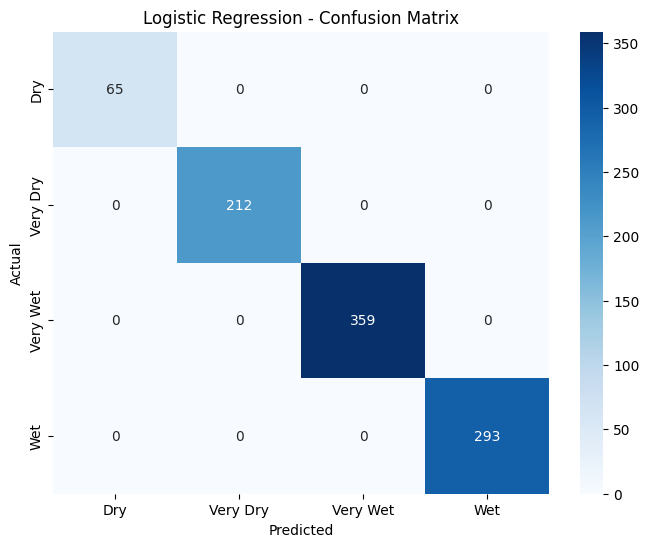


Random Forest Classifier - Cross-validation scores: [1. 1. 1. 1. 1.]
Mean cross-validation score: 1.0
Random Forest Classifier - Test Accuracy: 1.0

Random Forest Classifier - Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        65
           1       1.00      1.00      1.00       212
           2       1.00      1.00      1.00       359
           3       1.00      1.00      1.00       293

    accuracy                           1.00       929
   macro avg       1.00      1.00      1.00       929
weighted avg       1.00      1.00      1.00       929



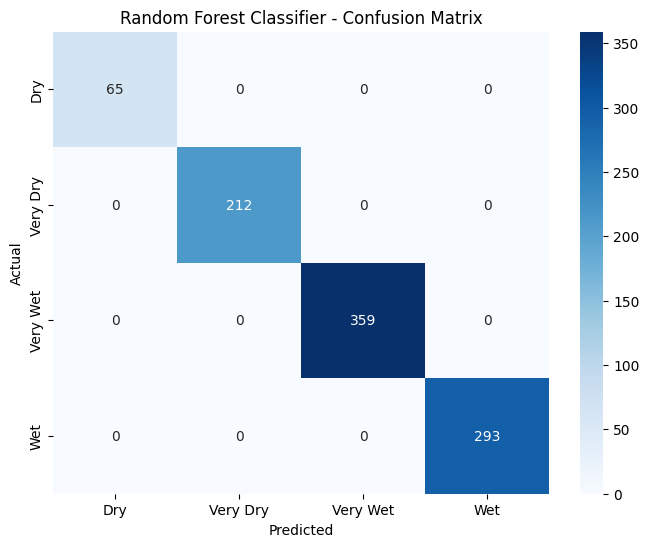


Gradient Boosting Classifier - Cross-validation scores: [1. 1. 1. 1. 1.]
Mean cross-validation score: 1.0
Gradient Boosting Classifier - Test Accuracy: 1.0

Gradient Boosting Classifier - Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        65
           1       1.00      1.00      1.00       212
           2       1.00      1.00      1.00       359
           3       1.00      1.00      1.00       293

    accuracy                           1.00       929
   macro avg       1.00      1.00      1.00       929
weighted avg       1.00      1.00      1.00       929



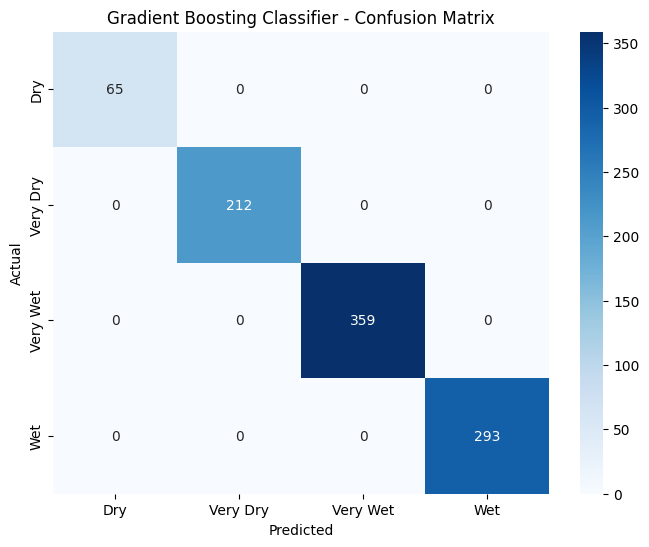


K-Nearest Neighbors - Cross-validation scores: [0.97846568 0.96635262 0.96769852 0.95962315 0.98247978]
Mean cross-validation score: 0.9709239514897353
K-Nearest Neighbors - Test Accuracy: 0.9806243272335845

K-Nearest Neighbors - Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.88      0.88        65
           1       0.98      0.97      0.98       212
           2       0.99      1.00      1.00       359
           3       0.98      0.99      0.99       293

    accuracy                           0.98       929
   macro avg       0.96      0.96      0.96       929
weighted avg       0.98      0.98      0.98       929



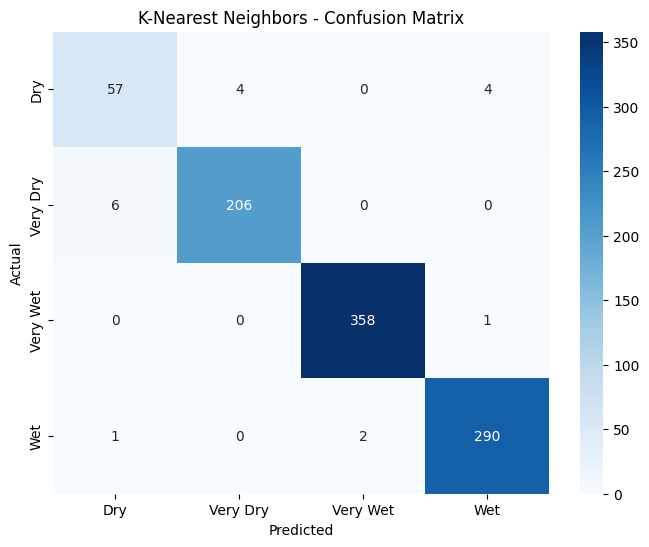

In [ ]:
for name, model in models:
    # Cross-validation scores
    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')
    print(f"\n{name} - Cross-validation scores: {cv_scores}")
    print(f"Mean cross-validation score: {cv_scores.mean()}")

    # Train the model on the full training set
    model.fit(X_train, y_train)

    # Predict on the test set
    y_pred = model.predict(X_test)

    # Evaluate performance
    test_accuracy = accuracy_score(y_test, y_pred)
    print(f"{name} - Test Accuracy: {test_accuracy}")

    # Store results for comparison
    model_names.append(name)
    cv_scores_means.append(cv_scores.mean())
    test_accuracies.append(test_accuracy)

    # If this model has the best combination of cross-validation and test accuracy, save it as the best model
    if cv_scores.mean() > best_cv_score and test_accuracy > best_score:
        best_score = test_accuracy
        best_cv_score = cv_scores.mean()
        best_model = model
        best_model_name = name

    # Print classification report
    print(f"\n{name} - Classification Report:")
    print(classification_report(y_test, y_pred))

    # Plot Confusion Matrix
    conf_matrix = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()


The best model based on cross-validation and test accuracy is: Logistic Regression with an accuracy of 1.0000 and a cross-validation score of 0.9989

Model Performance Comparison:
                          Model  Mean Cross-validation Score  Test Accuracy
0           Logistic Regression                     0.998923       1.000000
1      Random Forest Classifier                     1.000000       1.000000
2  Gradient Boosting Classifier                     1.000000       1.000000
3           K-Nearest Neighbors                     0.970924       0.980624


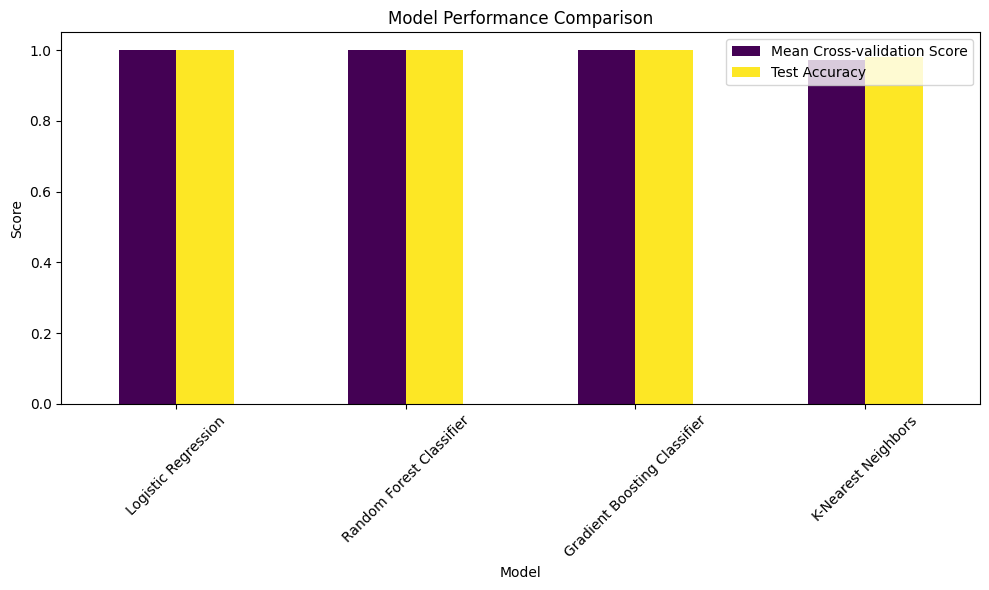

In [ ]:
# 9. Output the best model
print(f"\nThe best model based on cross-validation and test accuracy is: {best_model_name} with an accuracy of {best_score:.4f} and a cross-validation score of {best_cv_score:.4f}")

# 10. Create a summary table to compare model performance
results_df = pd.DataFrame({
    'Model': model_names,
    'Mean Cross-validation Score': cv_scores_means,
    'Test Accuracy': test_accuracies
})

# Display the table
print("\nModel Performance Comparison:")
print(results_df)

# 11. Create a bar plot for comparison
results_df.set_index('Model')[['Mean Cross-validation Score', 'Test Accuracy']].plot(kind='bar', figsize=(10, 6), cmap='viridis')
plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.xlabel('Model')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

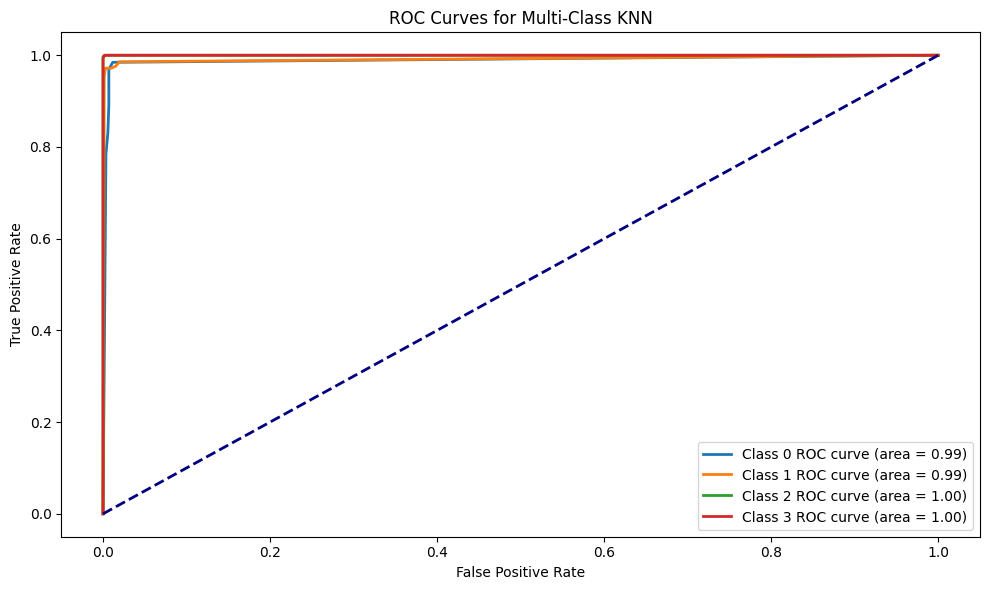

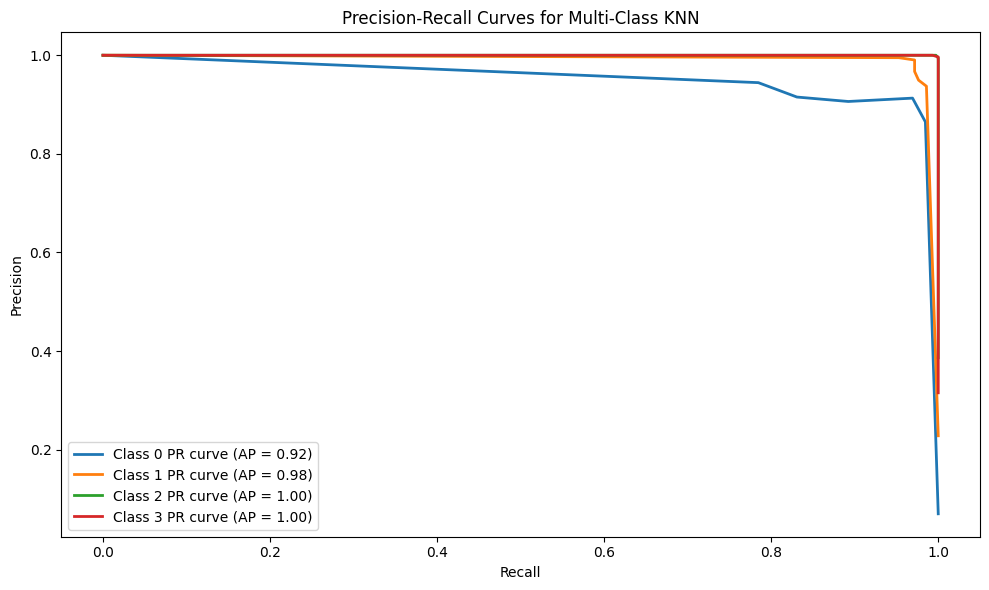

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.preprocessing import label_binarize
import numpy as np
from sklearn.neighbors import KNeighborsClassifier

# 1. Fit the KNN model and predict the probabilities
knn_model = KNeighborsClassifier()
knn_model.fit(X_train_scaled, y_train)

# Predict class probabilities for ROC and Precision-Recall curves
y_prob = knn_model.predict_proba(X_test_scaled)

# 2. Binarize the true labels for multi-class ROC computation
y_test_binarized = label_binarize(y_test, classes=np.unique(y_test))  # Binarize y_test for multi-class ROC
n_classes = y_test_binarized.shape[1]

# --- ROC Curve Plot ---
plt.figure(figsize=(10, 6))
for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_test_binarized[:, i], y_prob[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f'Class {i} ROC curve (area = {roc_auc:.2f})')

# Plot the diagonal line for random classifier
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.title('ROC Curves for Multi-Class KNN')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

# --- Precision-Recall Curve Plot ---
plt.figure(figsize=(10, 6))
for i in range(n_classes):
    precision, recall, _ = precision_recall_curve(y_test_binarized[:, i], y_prob[:, i])
    average_precision = average_precision_score(y_test_binarized[:, i], y_prob[:, i])
    plt.plot(recall, precision, lw=2, label=f'Class {i} PR curve (AP = {average_precision:.2f})')

plt.title('Precision-Recall Curves for Multi-Class KNN')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()
